# Modularity on the Karate Club Graph: Recursive Spectral Bisection

**DSC212 · Graph Theory Module · Research Assignment**

**Name:** `Juwariah Khaliqah` &nbsp;|&nbsp; **Roll number:** `IMS25101`

---

## Overview

In this notebook I implement Newman's (2006) spectral modularity method from scratch, using only NumPy and NetworkX, and apply it recursively to Zachary's Karate Club network. The notebook is organised around the five tasks in the handout:

1. Recursive spectral modularity partitioning (Sections 3 and 4)
2. A drawing of the graph after every split, one colour per community (Section 5)
3. Degree, betweenness, closeness and clustering after every split (Section 6)
4. Evolution of every metric for every node (Section 7)
5. Discussion (Section 8)

**Convention used throughout.** *Iteration 0* is the untouched graph (one community). *Iteration t* is the partition obtained after the *t*-th successful split. Nodes are numbered 1 to 34, as in the handout, whereas NetworkX numbers them 0 to 33.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

try:
    from IPython.display import display
except ImportError:
    display = print

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

TOL = 1e-9   # eigenvalues smaller than this are treated as zero

print("numpy   ", np.__version__)
print("pandas  ", pd.__version__)
print("networkx", nx.__version__)

numpy    2.5.4
pandas   3.0.6
networkx 3.7


## 2. Data and the modularity matrix

The network has 34 members and 78 ties. I relabel the nodes 1..34 and keep the original `club` attribute from NetworkX (`"Mr. Hi"` or `"Officer"`), which records the faction each member actually joined after the split. It is **not** used by the algorithm; I only use it at the end to check the result.

For an undirected graph with adjacency matrix $A$, degree vector $k$ and $m$ edges, the modularity matrix is

$$B = A - \frac{k k^{\top}}{2m}, \qquad Q(s) = \frac{1}{4m}\, s^{\top} B s ,$$

where $s_i = \pm 1$ labels the side of the split that node $i$ is on (Newman, 2006). The term $k_i k_j / 2m$ is the expected number of edges between $i$ and $j$ in a random graph with the same degrees.

In [2]:
karate = nx.karate_club_graph()

G = nx.relabel_nodes(karate, {i: i + 1 for i in karate.nodes})   # nodes 1..34
faction = {v: G.nodes[v]["club"] for v in G}                     # ground truth, used only for evaluation at the end
G = nx.Graph(G.edges())                                          # plain unweighted graph without attributes

nodes = sorted(G.nodes)                          # [1, ..., 34]
pos_of = {v: i for i, v in enumerate(nodes)}     # node label -> row/column index in matrices
n, m = G.number_of_nodes(), G.number_of_edges()
print(f"n = {n}, m = {m}, connected: {nx.is_connected(G)}")

# one fixed layout, reused for every drawing
layout = nx.spring_layout(G, seed=7)

n = 34, m = 78, connected: True


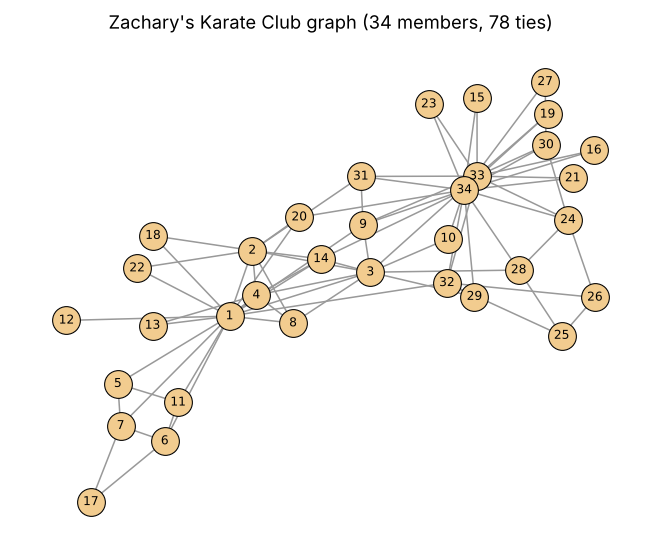

In [3]:
# The Karate Club graph itself: 34 members (nodes) and 78 ties (edges)
fig, ax = plt.subplots(figsize=(7.5, 6))
nx.draw_networkx_edges(G, layout, ax=ax, edge_color="#999999", width=1)
nx.draw_networkx_nodes(G, layout, ax=ax, node_color="#F2CC8F", node_size=330, edgecolors="black", linewidths=0.7)
nx.draw_networkx_labels(G, layout, ax=ax, font_size=8)
ax.set_title("Zachary's Karate Club graph (34 members, 78 ties)")
ax.axis("off")
plt.show()

In [4]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
k = A.sum(axis=1)
B = A - np.outer(k, k) / (2 * m)

# Sanity checks from the handout
assert np.allclose(B, B.T),              "Proposition 1: B must be symmetric"
assert np.allclose(B @ np.ones(n), 0),   "Proposition 2: B @ 1 must be 0"
assert np.isclose(k.sum(), 2 * m)

def Q_of(partition):
    # Modularity of a partition given as a list of node lists: Q = (1/2m) * sum_c sum_{i,j in c} B_ij.
    total = 0.0
    for group in partition:
        idx = [pos_of[v] for v in group]
        total += B[np.ix_(idx, idx)].sum()
    q = total / (2 * m)
    return 0.0 if abs(q) < 1e-12 else q

print("B is symmetric, B @ 1 = 0, and Q(everyone in one community) =", Q_of([nodes]))

B is symmetric, B @ 1 = 0, and Q(everyone in one community) = 0.0


## 3. Spectral bipartition of one community

To split a community $C$:

1. Take the block $B^{(C)}$ of $B$ whose rows and columns are indexed by $C$.
2. Compute its leading eigenpair $(\lambda_1^{(C)}, u_1^{(C)})$. Since $B^{(C)}$ is real symmetric, `numpy.linalg.eigh` is appropriate and returns real eigenvalues with orthonormal eigenvectors.
3. If $\lambda_1^{(C)} \le 0$ then $s^{\top}B^{(C)}s \le \lambda_1^{(C)}|C| \le 0$ for every $s\in\{\pm1\}^{|C|}$ (Theorem 3), so $C$ is indivisible.
4. Otherwise put $i$ in $C^{+}$ if $(u_1)_i > 0$ and in $C^{-}$ if not.

The relaxation from $s\in\{\pm1\}^n$ to $\|s\|_2=1$ is what makes this work: by Rayleigh–Ritz the maximum of $s^\top B s$ over unit vectors is $\lambda_1$, attained at $u_1$.

In [5]:
def leading_eigenpair(M):
    # Largest eigenvalue and a corresponding unit eigenvector of a symmetric matrix.
    vals, vecs = np.linalg.eigh(M)       # ascending order
    return float(vals[-1]), vecs[:, -1]


def try_split(group):
    # Attempt to bisect `group`. Returns (lambda_1, plus, minus), with plus = minus = None if it cannot be split.
    idx = [pos_of[v] for v in group]
    B_C = B[np.ix_(idx, idx)]
    lam, u = leading_eigenpair(B_C)

    if lam <= TOL:                                   # stopping rule: lambda_1 <= 0
        return lam, None, None

    plus  = [v for v, x in zip(group, u) if x > 0]
    minus = [v for v, x in zip(group, u) if x <= 0]
    if not plus or not minus:                        # all signs equal: no usable bipartition
        return lam, None, None
    # orientation of u is arbitrary, so put the side containing the smallest node label first
    if min(minus) < min(plus):
        plus, minus = minus, plus
    return lam, plus, minus


lam, plus, minus = try_split(nodes)
s = np.array([1 if v in plus else -1 for v in nodes])
print(f"lambda_1 of the full B : {lam:.4f}")
print(f"group 1 ({len(plus):2d} nodes): {sorted(plus)}")
print(f"group 2 ({len(minus):2d} nodes): {sorted(minus)}")
print(f"Q via s'Bs/4m          : {s @ B @ s / (4 * m):.4f}")
print(f"Q via block sums       : {Q_of([plus, minus]):.4f}")
print(f"Q via networkx         : {nx.community.modularity(G, [set(plus), set(minus)]):.4f}")

lambda_1 of the full B : 4.9771
group 1 (16 nodes): [1, 2, 3, 4, 5, 6, 7, 8, 11, 12, 13, 14, 17, 18, 20, 22]
group 2 (18 nodes): [9, 10, 15, 16, 19, 21, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34]
Q via s'Bs/4m          : 0.3715
Q via block sums       : 0.3715
Q via networkx         : 0.3715


## 4. Recursive bisection

I keep a work queue of communities that still have to be tested. Each community is taken from the front of the queue and tested. If it splits, both halves are stored in the current partition and put at the back of the queue. If it does not split, it is final. Every successful split produces one new snapshot of the partition, so `history[t]` is the partition at iteration $t$.

Each community has an integer id that never changes while it exists: the $C^{+}$ half inherits the id of its parent, and $C^{-}$ gets a new id. This lets a community keep its colour across figures.

In [6]:
from collections import deque

partition = {0: list(nodes)}                    # community id -> member list (current partition)
history = [{c: list(g) for c, g in partition.items()}]
test_log = []                                   # one record per community tested
next_id = 1

queue = deque([0])
while queue:
    cid = queue.popleft()
    group = partition[cid]
    lam, plus, minus = try_split(group)

    if plus is None:
        reason = "lambda_1 <= 0" if lam <= TOL else "lambda_1 > 0 but signs of u_1 all equal"
        test_log.append(dict(community=cid, size=len(group), lambda_1=lam, outcome=f"final ({reason})"))
        continue

    new_cid, next_id = next_id, next_id + 1
    partition[cid], partition[new_cid] = plus, minus
    history.append({c: list(g) for c, g in partition.items()})
    test_log.append(dict(community=cid, size=len(group), lambda_1=lam,
                         outcome=f"split {len(plus)}+{len(minus)} -> iteration {len(history) - 1}"))
    queue.extend([cid, new_cid])

T = len(history)       # number of snapshots, iterations 0..T-1

for snap in history:   # each snapshot must contain every node exactly once
    assert sorted(v for g in snap.values() for v in g) == nodes

print("Communities tested, in order:")
display(pd.DataFrame(test_log).round(4))

summary = pd.DataFrame({
    "communities": [len(s_) for s_ in history],
    "sizes": [sorted((len(g) for g in s_.values()), reverse=True) for s_ in history],
    "Q": [Q_of(list(s_.values())) for s_ in history],
}).rename_axis("iteration")
print("\nPartition after each iteration:")
display(summary.round(4))

print("Final communities:")
for cid, g in partition.items():
    print(f"  community {cid} ({len(g):2d} nodes): {sorted(g)}")

Communities tested, in order:
   community  size  lambda_1                                          outcome
0          0    34    4.9771                       split 16+18 -> iteration 1
1          0    16    2.9441                        split 10+6 -> iteration 2
2          1    18    2.5041                        split 13+5 -> iteration 3
3          0    10    2.5712  final (lambda_1 > 0 but signs of u_1 all equal)
4          2     6    2.1480                         split 5+1 -> iteration 4
5          1    13    2.3563  final (lambda_1 > 0 but signs of u_1 all equal)
6          3     5    1.8759  final (lambda_1 > 0 but signs of u_1 all equal)
7          2     5    2.1470  final (lambda_1 > 0 but signs of u_1 all equal)
8          4     1   -0.0064                            final (lambda_1 <= 0)

Partition after each iteration:
           communities              sizes       Q
iteration                                        
0                    1               [34]  0.0000
1      

### Check against the real split of the club

The first split should be compared with the actual fission of the club. For each member we know whether they followed Mr. Hi or the Officer (the club president).

In [7]:
first = history[1]
ids = sorted(first)
side_a, side_b = set(first[ids[0]]), set(first[ids[1]])
hi = {v for v in nodes if faction[v] == "Mr. Hi"}
officer = set(nodes) - hi

# the two sides may be matched to the two factions in either order; take the better matching
match1 = len(side_a & hi) + len(side_b & officer)
match2 = len(side_a & officer) + len(side_b & hi)
best = max(match1, match2)
wrong = sorted((side_a & officer) | (side_b & hi)) if match1 >= match2 else sorted((side_a & hi) | (side_b & officer))

print(f"Members whose side the first spectral split predicts correctly: {best} / {n}  ({best / n:.1%})")
print(f"Misplaced member(s): {wrong}")
print("Faction of the misplaced member(s):", {v: faction[v] for v in wrong})

Members whose side the first spectral split predicts correctly: 33 / 34  (97.1%)
Misplaced member(s): [9]
Faction of the misplaced member(s): {9: 'Mr. Hi'}


## 5. The graph after each split

Every panel uses the same layout, so a node never moves. Colour shows the community, the text is the node ID, and dashed red edges join nodes of different communities (the ties that have been "cut" so far).

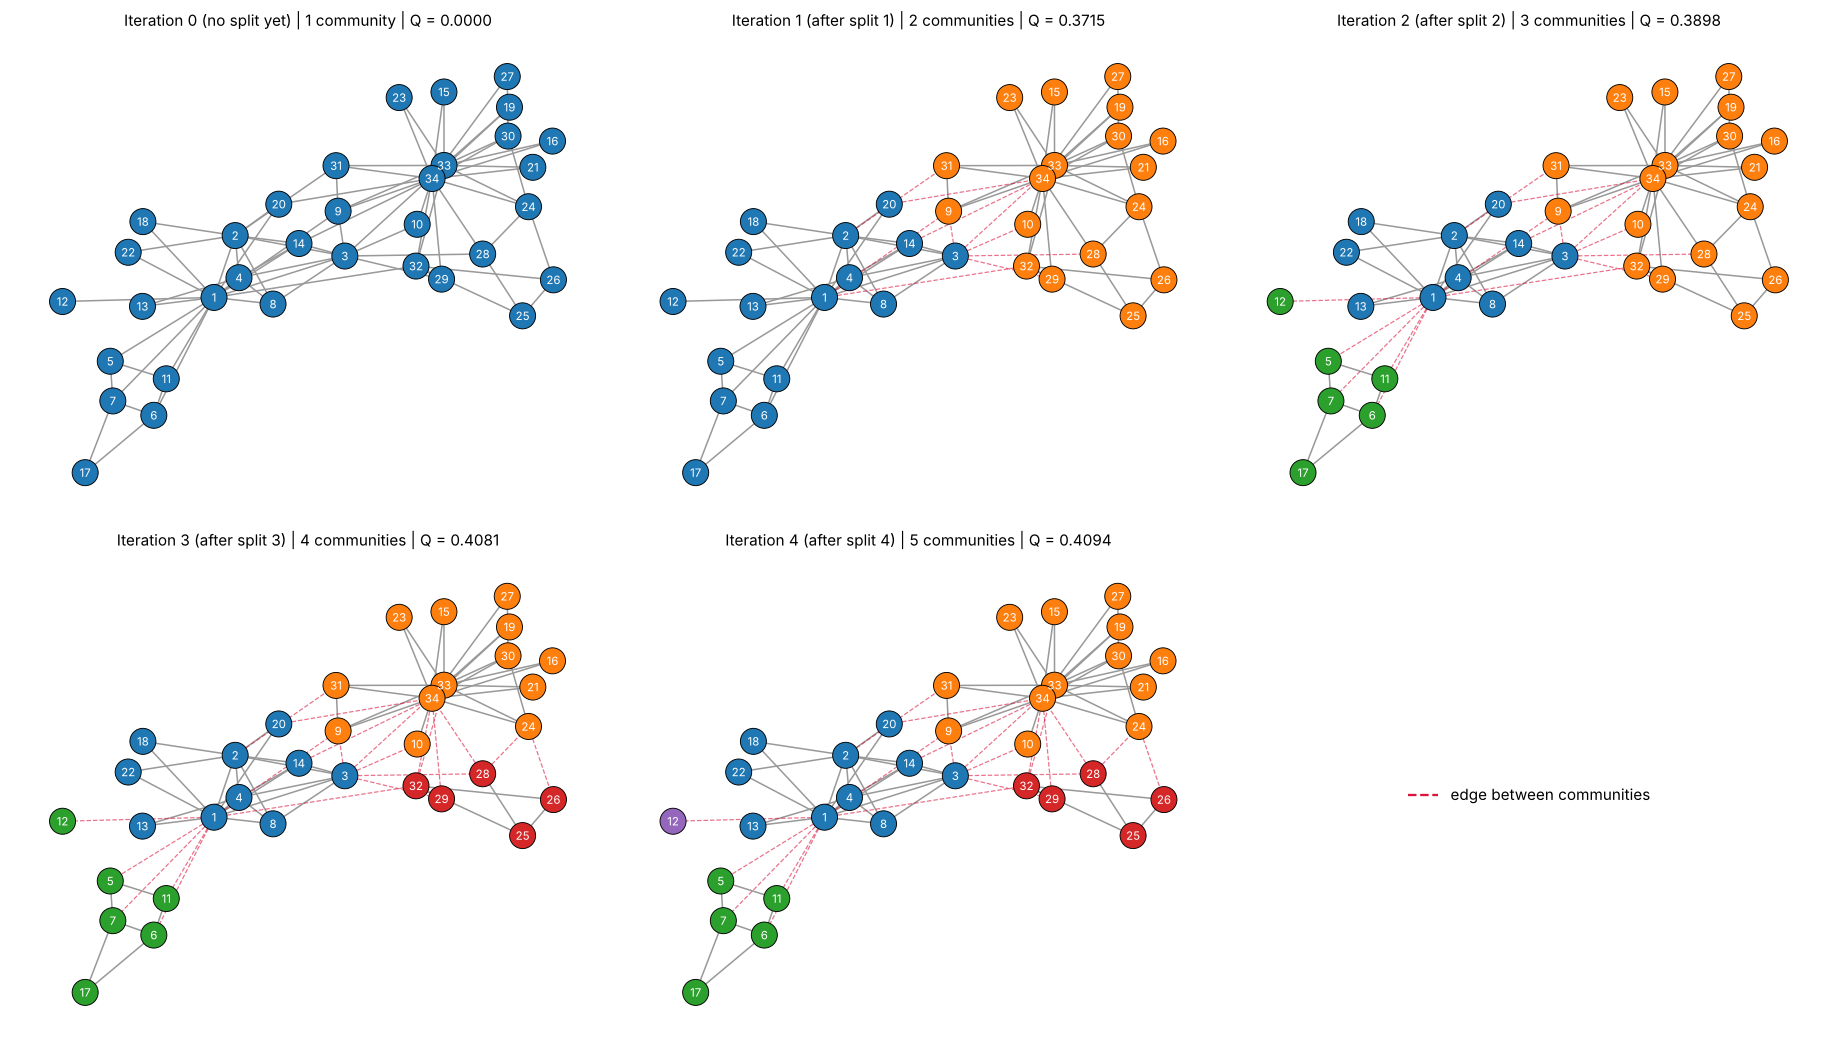

In [8]:
COLOURS = plt.get_cmap("tab10").colors          # community id -> colour; an id keeps its colour while it exists

def text_colour(rgb):
    r, g, b = rgb
    return "black" if 0.299 * r + 0.587 * g + 0.114 * b > 0.6 else "white"

def draw_snapshot(ax, snap, title):
    comm_of = {v: c for c, g in snap.items() for v in g}
    inside = [(u, v) for u, v in G.edges if comm_of[u] == comm_of[v]]
    across = [(u, v) for u, v in G.edges if comm_of[u] != comm_of[v]]
    nx.draw_networkx_edges(G, layout, edgelist=inside, ax=ax, edge_color="#999999", width=1)
    nx.draw_networkx_edges(G, layout, edgelist=across, ax=ax, edge_color="crimson", width=0.8, style="dashed", alpha=0.6)
    nx.draw_networkx_nodes(G, layout, nodelist=nodes, ax=ax, node_size=290, edgecolors="black", linewidths=0.6,
                           node_color=[COLOURS[comm_of[v] % 10] for v in nodes])
    for v in nodes:
        ax.text(*layout[v], str(v), ha="center", va="center", fontsize=7.5, color=text_colour(COLOURS[comm_of[v] % 10]))
    ax.set_title(title, fontsize=10)
    ax.axis("off")

cols = 3
rows = -(-T // cols)
fig, axes = plt.subplots(rows, cols, figsize=(5.6 * cols, 4.8 * rows))
axes = np.atleast_1d(axes).ravel()
for t, snap in enumerate(history):
    q = Q_of(list(snap.values()))
    label = "no split yet" if t == 0 else f"after split {t}"
    draw_snapshot(axes[t], snap, f"Iteration {t} ({label}) | {len(snap)} communit{"y" if len(snap)==1 else "ies"} | Q = {q:.4f}")
for ax in axes[T:]:
    ax.axis("off")
axes[-1].legend(handles=[Line2D([], [], color="crimson", ls="--", label="edge between communities")],
                loc="center", frameon=False)
plt.tight_layout()
plt.show()

## 6. Node metrics after each split

A split only assigns labels, it does not delete any edge. If the four metrics were computed on the full graph $G$ after every split, they would be the same at every iteration and there would be nothing to plot. So at iteration $t$ I compute each metric **inside the node's own community**, i.e. on the subgraph of $G$ induced by that community. This answers the question "how does this node look from within the group it now belongs to?". Iteration 0 is the whole graph.

The four NetworkX functions are `degree_centrality`, `betweenness_centrality`, `closeness_centrality` and `clustering`. Values are stored in the dictionary `metrics[t]`, keyed by iteration number. A community with a single member has no ties, so all its metrics are set to 0.

In [9]:
metric_funcs = {
    "Degree centrality":      nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality":   nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

def metrics_for_partition(snap):
    out = {name: {} for name in metric_funcs}
    for group in snap.values():
        if len(group) == 1:                      # singleton community: no ties
            for name in metric_funcs:
                out[name][group[0]] = 0.0
            continue
        sub = G.subgraph(group)
        for name, fn in metric_funcs.items():
            out[name].update(fn(sub))
    return out

metrics = {t: metrics_for_partition(snap) for t, snap in enumerate(history)}   # metrics[iteration][metric][node]

# at iteration 0 the community is the whole graph, so the values must equal plain NetworkX calls on G
for name, fn in metric_funcs.items():
    assert metrics[0][name] == fn(G)

# one table per metric: rows = nodes, columns = iterations
tables = {}
for name in metric_funcs:
    tab = pd.DataFrame({t: metrics[t][name] for t in range(T)}).loc[nodes]
    tab.index.name, tab.columns.name = "node", "iteration"
    tables[name] = tab

for name, tab in tables.items():
    print(f"\n{name}")
    display(tab.round(3))


Degree centrality
iteration      0      1      2      3      4
node                                        
1          0.485  0.933  1.000  1.000  1.000
2          0.273  0.533  0.889  0.889  0.889
3          0.303  0.333  0.556  0.556  0.556
4          0.182  0.400  0.667  0.667  0.667
5          0.091  0.200  0.400  0.400  0.500
6          0.121  0.267  0.600  0.600  0.750
7          0.121  0.267  0.600  0.600  0.750
8          0.121  0.267  0.444  0.444  0.444
9          0.152  0.176  0.176  0.250  0.250
10         0.061  0.059  0.059  0.083  0.083
11         0.091  0.200  0.400  0.400  0.500
12         0.030  0.067  0.000  0.000  0.000
13         0.061  0.133  0.222  0.222  0.222
14         0.152  0.267  0.444  0.444  0.444
15         0.061  0.118  0.118  0.167  0.167
16         0.061  0.118  0.118  0.167  0.167
17         0.061  0.133  0.400  0.400  0.500
18         0.061  0.133  0.222  0.222  0.222
19         0.061  0.118  0.118  0.167  0.167
20         0.091  0.133  0.222  0.22

## 7. Evolution of the metrics

One panel per metric, one line per node. Line colour is the node's *final* community; thick lines are the five members with the highest degree in the full graph and they are labelled at the right edge, together with the three nodes whose value changed the most.

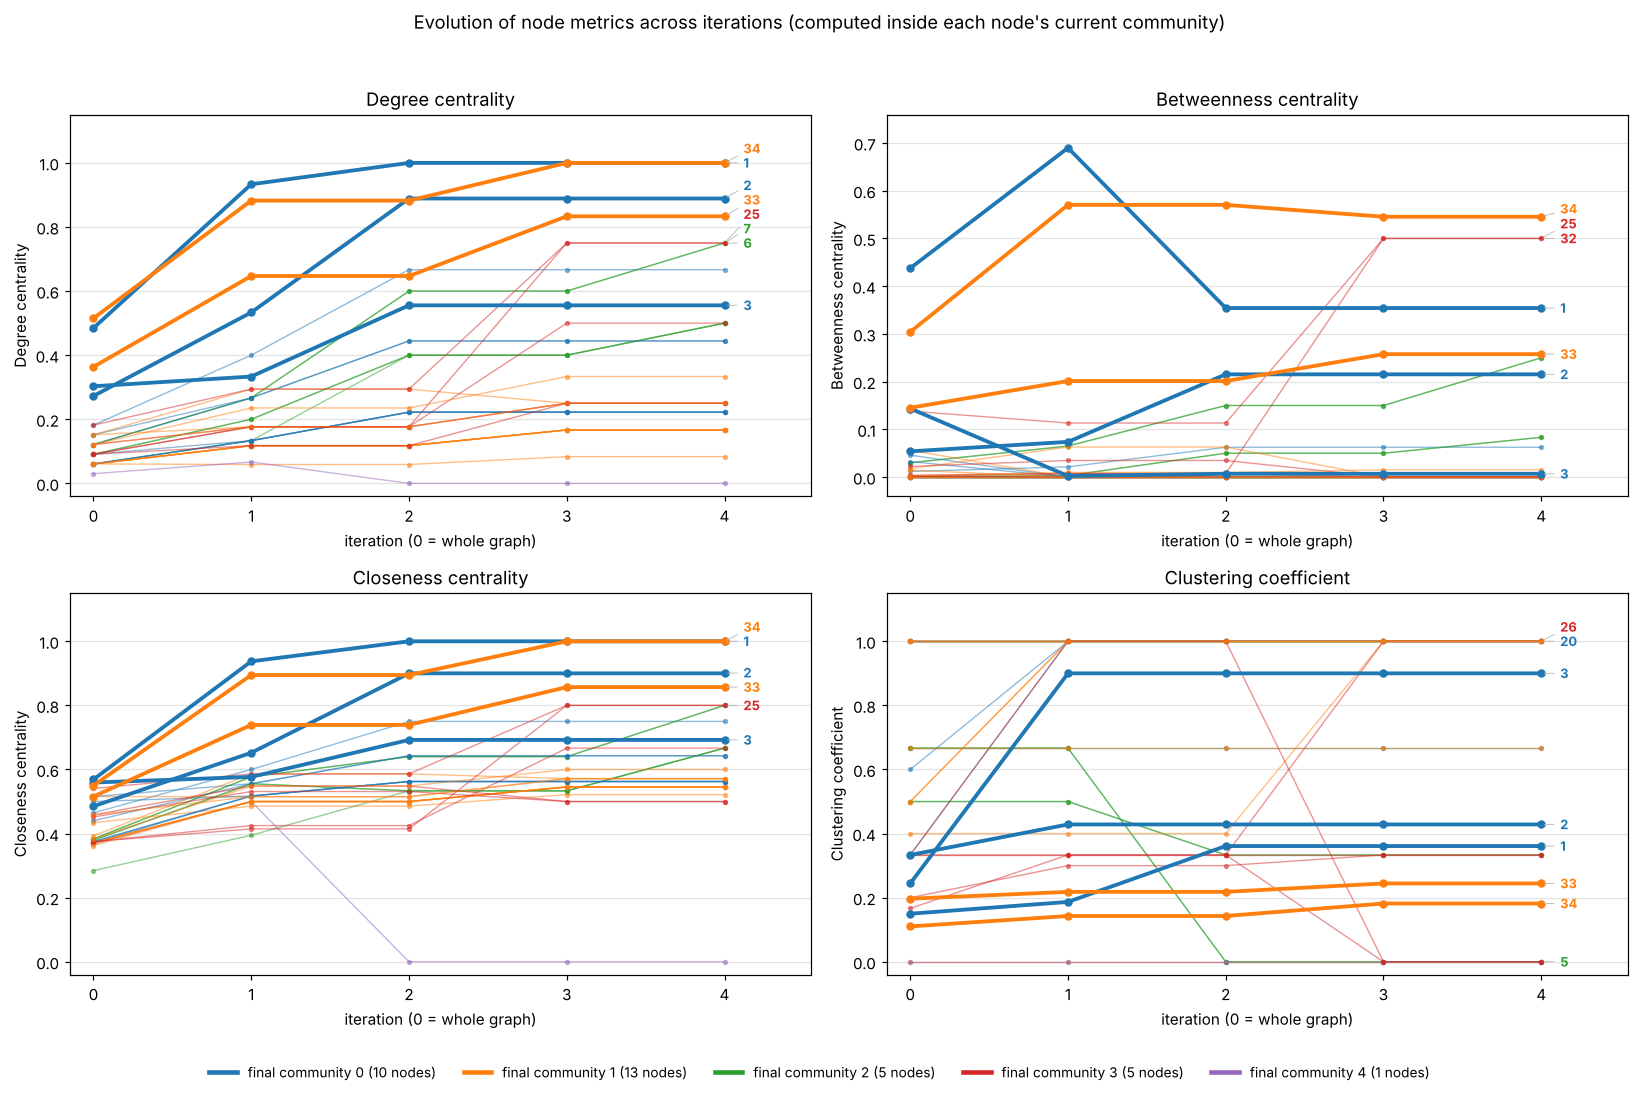

In [10]:
final_comm = {v: c for c, g in history[-1].items() for v in g}
deg = dict(G.degree())
top5 = sorted(nodes, key=lambda v: (-deg[v], v))[:5]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (name, tab) in zip(axes.ravel(), tables.items()):
    for v in nodes:
        big = v in top5
        ax.plot(range(T), tab.loc[v].values, marker="o", ms=4.5 if big else 2.5,
                lw=2.5 if big else 0.9, alpha=1 if big else 0.5, zorder=3 if big else 2,
                color=COLOURS[final_comm[v] % 10])

    movers = (tab[T - 1] - tab[0]).abs().sort_values(ascending=False).index[:3]
    to_label = sorted(set(top5) | set(movers), key=lambda v: tab.loc[v, T - 1])
    gap = 0.045 * (tab.values.max() - tab.values.min() + 1e-9)
    y, ys = -np.inf, {}
    for v in to_label:                    # nudge labels apart so that they do not overlap
        y = max(tab.loc[v, T - 1], y + gap)
        ys[v] = y
    for v in to_label:
        ax.annotate(str(v), xy=(T - 1, tab.loc[v, T - 1]), xytext=(T - 1 + 0.12, ys[v]), va="center",
                    fontsize=8.5, fontweight="bold", color=COLOURS[final_comm[v] % 10],
                    arrowprops=dict(arrowstyle="-", color="#bbbbbb", lw=0.6))
    ax.set_xticks(range(T))
    ax.set_xlim(-0.15, T - 1 + 0.55)
    ax.set_ylim(-0.04, 1.1 * max(tab.values.max(), max(ys.values())))
    ax.set_xlabel("iteration (0 = whole graph)")
    ax.set_ylabel(name)
    ax.set_title(name)
    ax.grid(axis="y", alpha=0.35)

legend = [Line2D([], [], color=COLOURS[c % 10], lw=3, label=f"final community {c} ({len(g)} nodes)")
          for c, g in history[-1].items()]
fig.legend(handles=legend, loc="lower center", ncol=len(legend), frameon=False, fontsize=9)
fig.suptitle("Evolution of node metrics across iterations (computed inside each node's current community)", fontsize=12)
plt.tight_layout(rect=(0, 0.04, 1, 0.96))
plt.show()

In [11]:
# Leaders per iteration, and the average of each metric over all nodes
def leaders(tab, top=3):
    row = {}
    for t in tab.columns:
        col = tab[t].sort_values(ascending=False, kind="stable")
        ties = int((col >= col.iloc[0] - 1e-9).sum())
        row[t] = (f"{ties} nodes tied at {col.iloc[0]:.3f}" if ties > top
                  else ", ".join(f"{v} ({x:.3f})" for v, x in col.head(top).items()))
    return row

print("Top nodes at each iteration:")
display(pd.DataFrame({name: leaders(tab) for name, tab in tables.items()}).T.rename_axis(columns="iteration"))

print("\nAverage over all 34 nodes:")
display(pd.DataFrame({name: tab.mean() for name, tab in tables.items()}).T.round(3).rename_axis(columns="iteration"))

Top nodes at each iteration:
iteration                                               0                                  1                                 2                                   3  \
Degree centrality       34 (0.515), 1 (0.485), 33 (0.364)  1 (0.933), 34 (0.882), 33 (0.647)  1 (1.000), 2 (0.889), 34 (0.882)    1 (1.000), 34 (1.000), 2 (0.889)   
Betweenness centrality  1 (0.438), 34 (0.304), 33 (0.145)  1 (0.690), 34 (0.570), 33 (0.201)  34 (0.570), 1 (0.354), 2 (0.215)  34 (0.545), 25 (0.500), 32 (0.500)   
Closeness centrality     1 (0.569), 3 (0.559), 34 (0.550)  1 (0.938), 34 (0.895), 33 (0.739)  1 (1.000), 2 (0.900), 34 (0.895)    1 (1.000), 34 (1.000), 2 (0.900)   
Clustering coefficient             11 nodes tied at 1.000             16 nodes tied at 1.000            16 nodes tied at 1.000              17 nodes tied at 1.000   

iteration                                                4  
Degree centrality         1 (1.000), 34 (1.000), 2 (0.889)  
Betweenness centra

## 8. Discussion

**Result of the partitioning.** The first spectral cut ($\lambda_1 = 4.977$) splits the club into 16 and 18 members with $Q = 0.372$. It agrees with the real fission for 33 of 34 members; the only mistake is member 9, who followed Mr. Hi but is placed with the president's side. Three further splits raise $Q$ to 0.409, giving communities of 10, 13, 5, 5 and 1 members (the single member is node 12). Splits 2 to 4 each add only about 0.02 or less, so most of the modularity comes from the first split.

**Which nodes stay central.** Nodes **1** and **34**, the instructor's and the administrator's hubs, are in the top three for degree centrality and closeness at every iteration. At iteration 0 node 34 has the highest degree (0.515) and node 1 the highest closeness (0.569) and betweenness (0.438). After the first split both are connected to almost everyone in their community, and from iteration 3 both reach 1.0 for degree and closeness. Node 33 is the next most consistent hub, and node 2 enters the top three of the 10-member community. Betweenness is more variable: node 1 leads at iterations 0 and 1, node 34 from iteration 2 on, and at iterations 3 and 4 nodes 25 and 32 tie for second place with 0.5.

**How community structure influences the metrics.**
* *Scale effect.* Inside a community of $r$ nodes the normaliser is $r-1$, not 33, so the averages grow mechanically: mean degree centrality goes from 0.139 to 0.423 and mean closeness from 0.426 to 0.639. A rise in these two metrics therefore says more about group size than about the node.
* *Betweenness* shows the structural change best. Nodes that bridged the two sides lose that role once the cross-community ties are gone: node 3 falls from 0.144 to 0.002 after the first split, and nodes 9, 14 and 20 go to 0. Node 1 first rises to 0.690 (it is the main broker of the 16-member group) and then falls to 0.354 when the group {5, 6, 7, 11, 17} is separated from it. The opposite happens in small groups: in {25, 26, 28, 29, 32} node 25 goes from 0.002 to 0.500 and node 32 from 0.113 to 0.500, although neither is a major broker in the whole club.
* *Closeness* mostly rises, because paths inside a community are short. The exception is node 12, whose only tie is to node 1: once it is separated from node 1 it has no neighbour in its community, so its closeness is 0 at iteration 2 and it becomes a one-member community at iteration 4.
* *Clustering* is the most erratic metric. It jumps for nodes whose neighbours lay on both sides of a cut (node 3 rises from 0.244 to 0.900, and nodes 9, 14, 20, 29 and 31 reach 1.0 after the first split). It falls for nodes whose triangles used a removed tie (nodes 5 and 11 drop from 0.667 to 0 once they are cut from node 1). The hubs 1, 33 and 34 stay at low clustering (0.361, 0.244 and 0.182 at the end) because they link many members who are not tied to each other. Between 11 and 17 nodes tie at 1.0 in every iteration, so clustering does not identify a leader.

**Overall.** Degree and closeness identify the same local hubs (1 and 34) however the club is divided, so they are the stable measures. Betweenness and clustering depend on which ties survive the cuts and change most for nodes near community boundaries, so they are the measures that describe the community structure itself.

**Limitations.** (i) Following the handout, I use the plain block $B^{(C)}$ of the global $B$. Newman's (2006) full method for repeated division adds a diagonal correction so that $B^{(C)}$ rows sum to zero, and that version may split some communities that are left whole here. (ii) A community can have $\lambda_1 > 0$ and yet give no split when every entry of $u_1$ has the same sign; the code treats such a community as final, and the test log in Section 4 marks these cases. (iii) The metrics are computed inside each community (Section 6), which is a modelling choice made because a split does not delete any edge.


## References

* Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582.
* Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research*, 33(4), 452–473.
* DSC212 research assignment handout, *Modularity on the Karate Club Graph*.